# 01 - Data Cleaning & Exploratory Data Analysis
MovieLens `ml-latest-small`. Goals: understand rating behaviour, sparsity and the long tail, since they drive every modelling choice.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from ml.data import build_processed
sns.set_theme(style='darkgrid'); plt.rcParams['figure.figsize'] = (8, 4)
d = build_processed()
movies, ratings, tags = d['movies'], d['ratings'], d['tags']
print(ratings.shape, movies.shape, tags.shape)

(100836, 4) (9742, 6) (3683, 4)


## 1. Cleaning summary
Duplicates and orphan ratings were dropped; year parsed from title; genres split; tags lower-cased.

In [2]:
print('missing ratings:', ratings.rating.isna().sum())
print('movies without year:', movies.year.isna().sum())
print('movies without genre:', (movies.genres_list.str.len() == 0).sum())
ratings.describe()

missing ratings: 0
movies without year: 13
movies without genre: 34


,userId,movieId,rating,timestamp
count,100836.000000,100836.000000,100836.000000,1.008360e+05
mean,326.127564,19435.295718,3.501557,1.205946e+09
std,182.618491,35530.987199,1.042529,2.162610e+08
min,1.000000,1.000000,0.500000,8.281246e+08
25%,177.000000,1199.000000,3.000000,1.019124e+09
50%,325.000000,2991.000000,3.500000,1.186087e+09
75%,477.000000,8122.000000,4.000000,1.435994e+09
max,610.000000,193609.000000,5.000000,1.537799e+09


## 2. Rating distribution
Ratings skew positive (users rate what they like), so a global-mean baseline is already strong and RMSE gains are small in absolute terms.

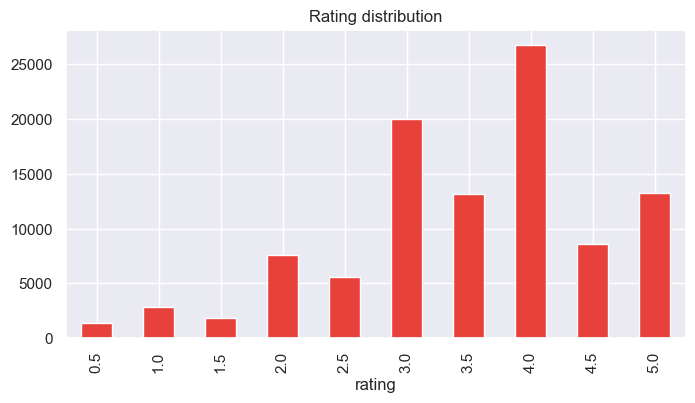

mean 3.502 std 1.043


In [3]:
ratings.rating.value_counts().sort_index().plot.bar(color='#E8403A')
plt.title('Rating distribution'); plt.xlabel('rating'); plt.show()
print('mean', ratings.rating.mean().round(3), 'std', ratings.rating.std().round(3))

## 3. Sparsity
A user-item matrix this empty is why neighbourhood methods struggle and matrix factorisation helps.

In [4]:
n_u, n_i = ratings.userId.nunique(), ratings.movieId.nunique()
sparsity = 1 - len(ratings) / (n_u * n_i)
print(f'users={n_u} items={n_i} ratings={len(ratings)} sparsity={sparsity:.2%}')

users=610 items=9724 ratings=100836 sparsity=98.30%


## 4. Long-tail popularity
A few blockbusters collect most ratings; most movies have very few. Popularity recommenders exploit the head, while coverage and novelty metrics expose the tail.

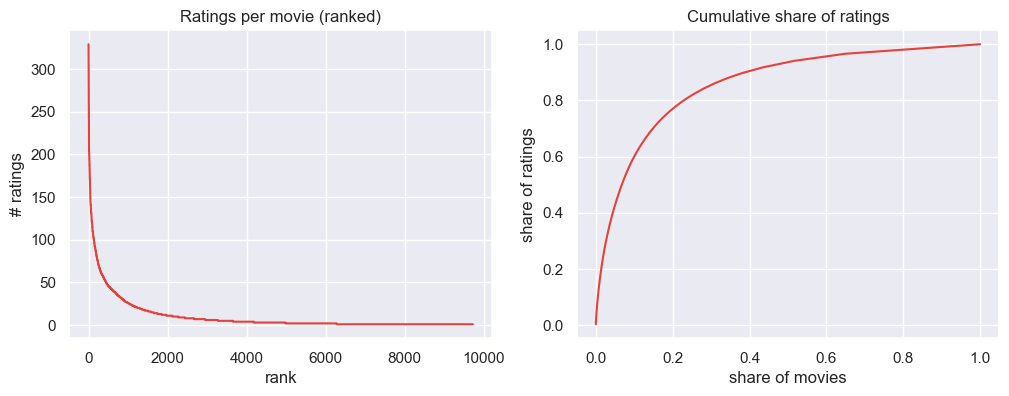

Top 20% of movies hold 77.0% of ratings
Movies with < 5 ratings: 62.5%


In [5]:
pop = ratings.groupby('movieId').size().sort_values(ascending=False).values
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(pop, color='#E8403A'); ax[0].set(title='Ratings per movie (ranked)', xlabel='rank', ylabel='# ratings')
ax[1].plot(np.arange(1, len(pop)+1)/len(pop), np.cumsum(pop)/pop.sum(), color='#E8403A')
ax[1].set(title='Cumulative share of ratings', xlabel='share of movies', ylabel='share of ratings')
plt.show()
top20 = int(0.2 * len(pop)); print(f'Top 20% of movies hold {pop[:top20].sum()/pop.sum():.1%} of ratings')
print(f'Movies with < 5 ratings: {(pop < 5).mean():.1%}')

## 5. Ratings per user
Heavy-tailed too; every user has >= 20 ratings (dataset guarantee), which makes per-user splitting feasible.

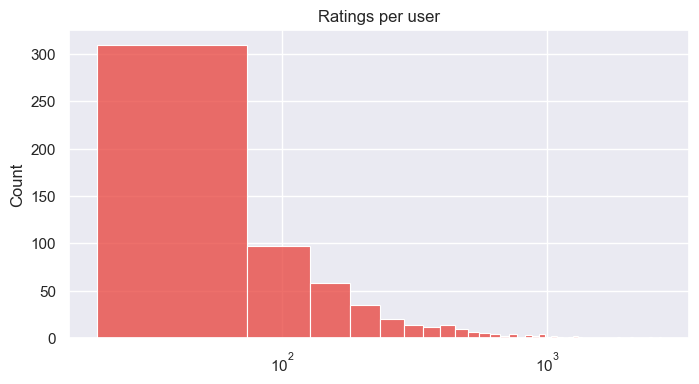

count     610.000000
mean      165.304918
std       269.480584
min        20.000000
25%        35.000000
50%        70.500000
75%       168.000000
max      2698.000000
dtype: float64


In [6]:
per_user = ratings.groupby('userId').size()
sns.histplot(per_user, bins=50, color='#E8403A'); plt.title('Ratings per user'); plt.xscale('log'); plt.show()
print(per_user.describe())

## 6. Genre distribution

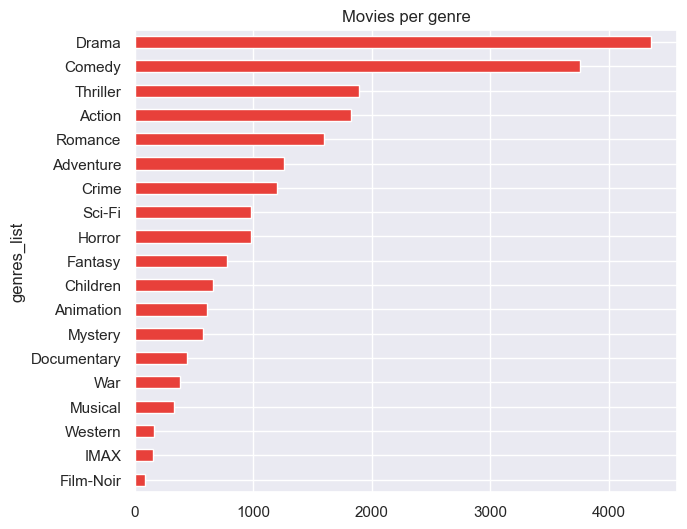

In [7]:
g = movies.explode('genres_list').genres_list.value_counts()
g.drop('', errors='ignore').sort_values().plot.barh(color='#E8403A', figsize=(7, 6))
plt.title('Movies per genre'); plt.show()

## 7. Rating by genre and release decade

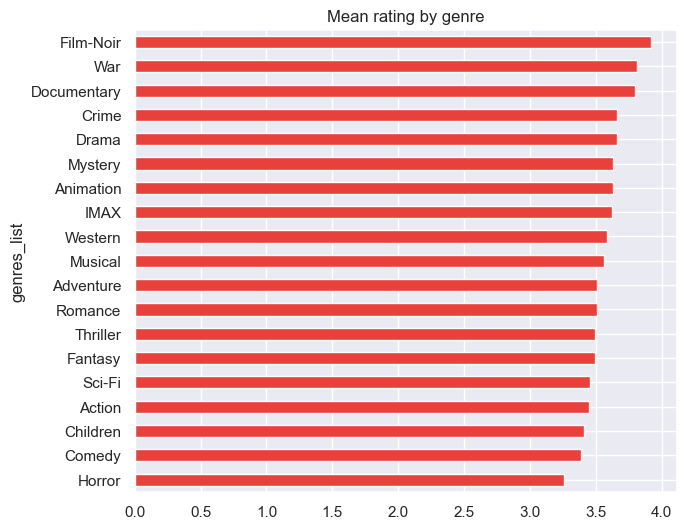

,mean,count
decade,,
1900,3.312500,8
1910,3.312500,8
1920,3.740000,125
1930,3.733624,687
1940,3.870572,1101
1950,3.845011,1784
1960,3.808083,2858
1970,3.775676,4995
1980,3.518355,12912


In [8]:
r = ratings.merge(movies[['movieId', 'genres_list', 'year']], on='movieId')
ge = r.explode('genres_list')
ge.groupby('genres_list').rating.mean().sort_values().plot.barh(color='#E8403A', figsize=(7, 6))
plt.title('Mean rating by genre'); plt.show()
r['decade'] = (r.year // 10 * 10)
r.groupby('decade').rating.agg(['mean', 'count']).dropna()

## 8. Tags and time span
Tags feed the content model; timestamps justify a temporal split.

In [9]:
print('tags:', len(tags), 'unique:', tags.tag.nunique(), 'movies tagged:', tags.movieId.nunique())
print(tags.tag.value_counts().head(15))
ts = pd.to_datetime(ratings.timestamp, unit='s')
print('ratings span', ts.min().date(), 'to', ts.max().date())

tags: 3683 unique: 1475 movies tagged: 1572
tag
in netflix queue      131
atmospheric            41
superhero              24
thought-provoking      24
surreal                24
funny                  24
disney                 23
sci-fi                 23
quirky                 22
religion               22
psychology             21
dark comedy            21
suspense               21
twist ending           20
visually appealing     20
Name: count, dtype: int64
ratings span 1996-03-29 to 2018-09-24


## Takeaways
- Sparse, long-tailed, positively skewed ratings.
- Popularity is a strong baseline; accuracy metrics alone reward it.
- Tail items need content features (cold start).
- Use a per-user temporal split to avoid leakage.